# TP Integrador — Modulación LoRa / FSCM

Grupo 8 — **Testigos de Vangelista**.

Integrantes:

- Castro, Victor José Arturo 
- Carreras, Leonor Victoria

> **Versión para el laboratorio.** Igual que `tp_final.ipynb`, pero sin las simulaciones de FER y BER ni la demostración con ruido simulado, para ejecutar directamente el enlace con el ADALM-Pluto.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

**Librerías**

Todo el trabajo se apoya en dos librerías: `numpy`, para generar y procesar las señales como vectores, y `matplotlib`, para graficarlas. Las señales nunca se recorren muestra por muestra: se operan completas, lo que hace el código más corto y más rápido. La librería que controla el SDR se importa recién en la sección del enlace, así que el transmisor y la simulación pueden ejecutarse sin tener la placa conectada.

In [2]:
# TRANSMISOR — 1. Parámetros del PHY y del preámbulo

SF = 8                          # bits por símbolo
SamplingRate = 1_000_000        # tasa del SDR [muestras/s]
B = SamplingRate                # el chirp barre exactamente la tasa de muestreo
M = 2 ** SF                     # muestras por símbolo = símbolos posibles
T = 1 / B                       # período de chip [s]
Ts = M * T                      # duración de un símbolo [s]
k = np.arange(M)                # índice de chip

fc = 915e6                      # portadora dentro de la banda 900-920 MHz

n_up = 8                        # up-chirps del preámbulo
n_down = 2                      # down-chirps completos
cuarto_down = True              # último 1/4 de down-chirp
n_simbolos = 10                 # símbolos del payload

tramas_en_buffer = 2            # tramas por captura del receptor
NFLAT = 50000                   # tramas por punto del canal FLAT
NSELECTIVE = 50000              # tramas por punto del canal selectivo
snr_fer_db = np.arange(-12, 0, 1)   # SNR = Eb/N0 [dB], de -12 a -1
semilla = 2024

print(f"SF = {SF} | M = {M} | B = {B/1e6:.3f} MHz | fc = {fc/1e6:.0f} MHz")
print(f"Símbolo = {Ts*1e6:.1f} µs | Preámbulo = {(n_up + n_down)*M + (M//4 if cuarto_down else 0)} muestras")
print(f"FER: NFLAT = {NFLAT} | NSELECTIVE = {NSELECTIVE} tramas por punto")

SF = 8 | M = 256 | B = 1.000 MHz | fc = 915 MHz
Símbolo = 256.0 µs | Preámbulo = 2624 muestras
FER: NFLAT = 50000 | NSELECTIVE = 50000 tramas por punto


**Parámetros del sistema**

Acá se fijan los valores que comparten el transmisor y el receptor. El más importante es el factor de ensanchamiento `SF = 8`: cada símbolo transporta 8 bits, hay `M = 256` símbolos posibles y cada uno dura 256 muestras. El chirp ocupa 1 MHz, la misma tasa a la que muestrea el SDR, y se transmite en 915 MHz. El preámbulo, que el receptor usa para encontrar el comienzo de cada trama, está formado por 8 chirps ascendentes, 2 descendentes y un cuarto de chirp descendente. Todos los valores derivados se calculan a partir de `SF`, de modo que al cambiarlo se ajusta el resto del sistema.

In [3]:
# TRANSMISOR — 2. De bits a símbolo (Ecuación 1)
def bits_a_simbolo(bits, SF=SF):
    """Convierte filas de bits (LSB primero) en símbolos enteros."""
    simbolos = []
    for fila in np.asarray(bits):
        fila = np.asarray(fila, dtype=np.int64).ravel()
        if fila.size != SF:
            raise ValueError("cada fila debe tener SF bits")
        simbolos.append(int(np.dot(fila, 2 ** np.arange(SF))))
    return np.asarray(simbolos)


generador_bits = np.random.default_rng(semilla)
bits_payload = generador_bits.integers(0, 2, size=(n_simbolos, SF))
simbolos_payload = bits_a_simbolo(bits_payload)

print("Bits del payload (LSB primero) -> símbolo:")
for fila, simbolo in zip(bits_payload, simbolos_payload):
    print(f"  {fila.tolist()} -> {simbolo:3d}")

Bits del payload (LSB primero) -> símbolo:
  [0, 1, 0, 0, 0, 0, 1, 1] -> 194
  [1, 1, 0, 0, 1, 0, 0, 0] ->  19
  [1, 0, 0, 0, 0, 1, 1, 1] -> 225
  [1, 0, 0, 1, 1, 0, 0, 0] ->  25
  [0, 1, 1, 1, 1, 1, 0, 0] ->  62
  [0, 0, 1, 0, 1, 0, 1, 1] -> 212
  [1, 0, 0, 0, 1, 1, 0, 0] ->  49
  [0, 0, 0, 0, 1, 0, 1, 0] ->  80
  [0, 1, 1, 0, 0, 1, 0, 0] ->  38
  [0, 0, 0, 1, 0, 1, 0, 0] ->  40


**De bits a símbolos**

El mensaje a transmitir empieza siendo una secuencia de bits aleatorios. Se agrupan de a 8, y cada grupo se convierte en un número entre 0 y 255 según la ecuación (1) del paper, tomando el primer bit como el menos significativo. Ese número es el símbolo que después se va a modular. Los bits se generan con una semilla fija, así que cada ejecución produce el mismo mensaje y los resultados se pueden repetir.

In [4]:
# TRANSMISOR — 3. Modulación de símbolo (Ecuaciones 2 y 3)
def up_chirp(M=M):
    """Chirp ascendente base, energía unitaria."""
    kk = np.arange(M)
    return (1.0 / np.sqrt(M)) * np.exp(1j * 2 * np.pi * (kk ** 2) / M)


def down_chirp(M=M):
    """Chirp descendente: el conjugado del ascendente."""
    return np.conj(up_chirp(M))


def down_chirp_demod(M=M):
    """Réplica usada para dechirpear (sin la escala 1/sqrt(M))."""
    kk = np.arange(M)
    return np.exp(-1j * 2 * np.pi * (kk ** 2) / M)


def modular(simbolos, M=M):
    """Genera la señal FSCM de una secuencia de símbolos."""
    kk = np.arange(M)
    partes = []
    for simbolo in np.asarray(simbolos).ravel():
        if not 0 <= int(simbolo) < M:
            raise ValueError(f"símbolo fuera de rango: {simbolo}")
        fase = 2 * np.pi * (((int(simbolo) + kk) % M) * kk) / M
        partes.append((1 / np.sqrt(M)) * np.exp(1j * fase))
    return np.concatenate(partes)


def preambulo(M=M, n_up=n_up, n_down=n_down, cuarto=cuarto_down):
    """Preámbulo: up-chirps, down-chirps y 1/4 de down-chirp."""
    partes = [np.tile(up_chirp(M), n_up)]
    if n_down:
        partes.append(np.tile(down_chirp(M), n_down))
    if cuarto:
        partes.append(down_chirp(M)[: M // 4])
    return np.concatenate(partes)


def longitud_preambulo(M=M, n_up=n_up, n_down=n_down, cuarto=cuarto_down):
    largo = n_up * M + n_down * M
    if cuarto:
        largo += M // 4
    return largo

**Modulación con chirps**

LoRa representa cada símbolo con un chirp: una señal cuya frecuencia crece linealmente y recorre toda la banda. Lo que distingue a un símbolo de otro es la frecuencia en la que arranca el barrido; al llegar al borde superior, la frecuencia vuelve a empezar desde abajo. Gracias a eso los 256 chirps posibles son ortogonales entre sí y el receptor puede distinguirlos sin ambigüedad (ecuaciones (2) y (3)). En este bloque se definen el chirp ascendente base, el descendente, la función que modula una secuencia de símbolos y la que arma el preámbulo. La señal queda en banda base: la portadora de 915 MHz la agrega el SDR.

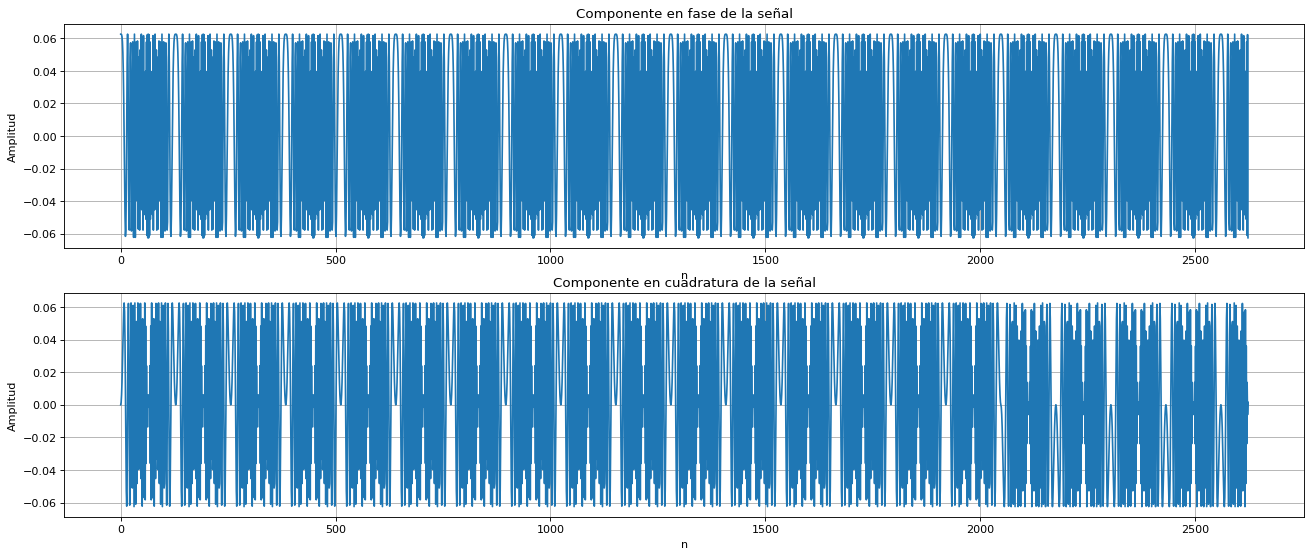

In [5]:
# TRANSMISOR — 4. Gráfico de la señal del preámbulo
def plotSignal(signal):
    #------------------------------- Componente en fase -------------------------------
    plt.figure(figsize=(20, 8), dpi=80, facecolor="w", edgecolor="k")
    plt.subplot(2, 1, 1)
    plt.plot(np.real(signal))
    plt.xlabel("n")
    plt.ylabel("Amplitud")
    plt.title("Componente en fase de la señal")
    plt.grid()
    #------------------------------- Componente en cuadratura ------------------------
    plt.subplot(2, 1, 2)
    plt.plot(np.imag(signal))
    plt.xlabel("n")
    plt.ylabel("Amplitud")
    plt.title("Componente en cuadratura de la señal")
    plt.grid()
    plt.show()


preambulo_ref = preambulo()
plotSignal(preambulo_ref)

**Preámbulo en el dominio del tiempo**

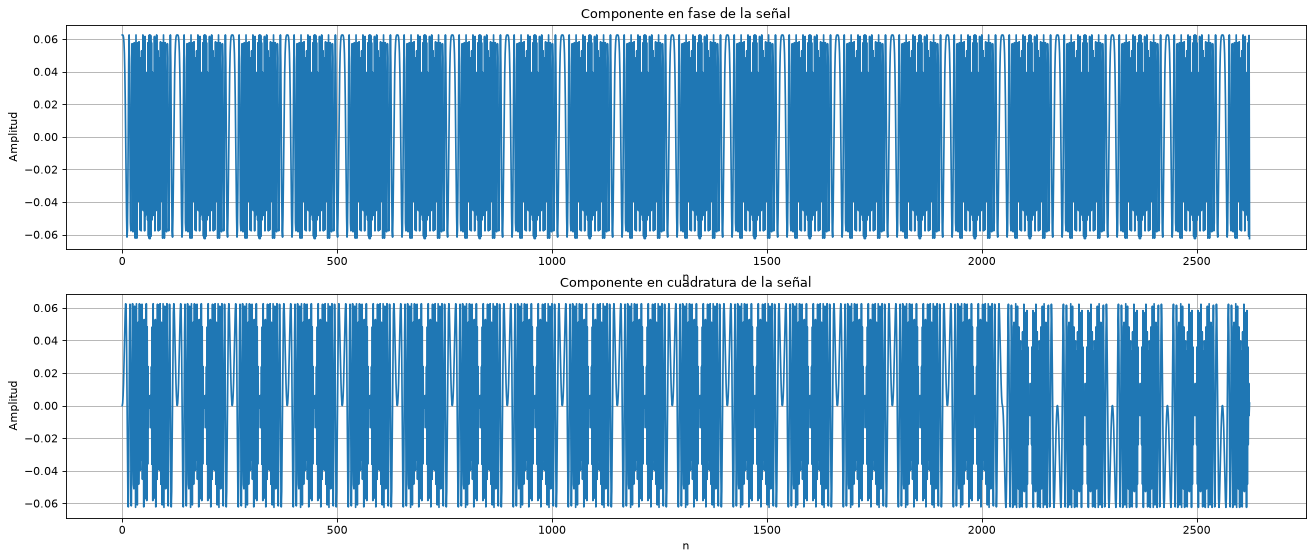

Se muestran las componentes en fase y en cuadratura del preámbulo. La amplitud se mantiene aproximadamente constante y lo que cambia es la frecuencia instantánea: el chirp barre la banda de forma lineal. La forma de onda corresponde a las ecuaciones (2)-(3) del paper, particularizadas para los símbolos del preámbulo. Sirve para verificar que la señal se construyó bien antes de agregar el payload.


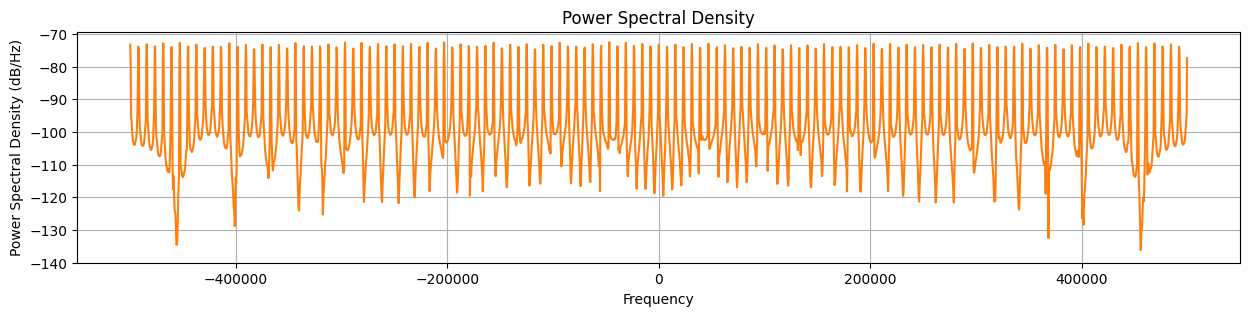

In [6]:
# TRANSMISOR — 5. Densidad espectral de potencia del preámbulo
def plotSpect(signal, samplingRate):
    plt.subplots(figsize=(15, 3))
    plt.grid()
    plt.title("Power Spectral Density")
    plt.psd(signal, NFFT=len(signal), Fs=samplingRate, color="C1")
    plt.show()


plotSpect(preambulo_ref, SamplingRate)

**Densidad espectral de potencia del preámbulo**

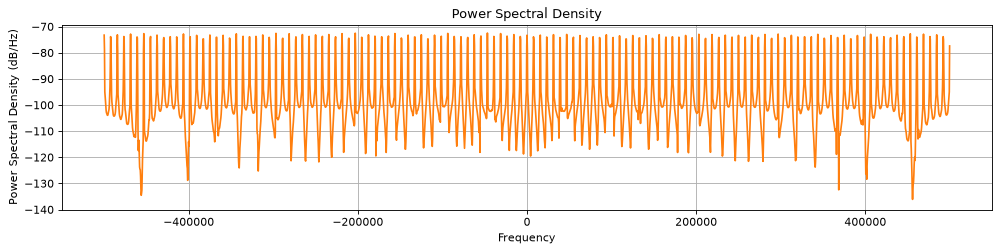

La PSD del preámbulo ocupa aproximadamente la banda de 1 MHz centrada en la portadora. El chirp recorre todas las frecuencias de la banda, por eso el espectro es bastante plano y no se concentra en unas pocas líneas. Es una consecuencia directa de la forma de onda de las ecuaciones (2)-(3). Confirma que la modulación no se sale de la banda útil.


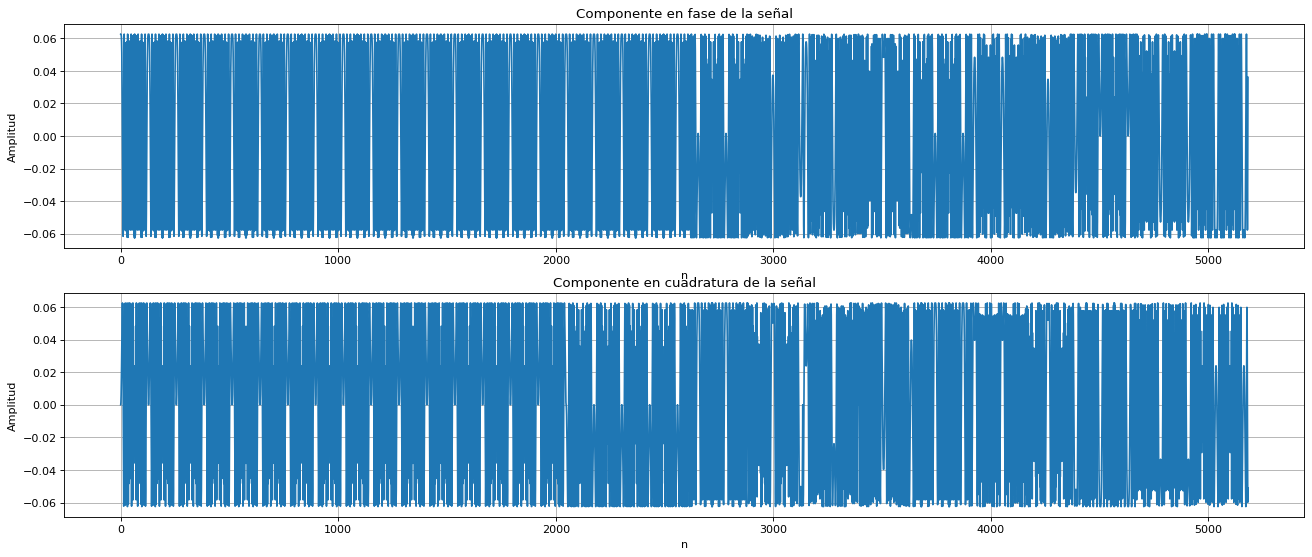

In [7]:
# TRANSMISOR — 6. Gráfico de la señal completa (trama)
trama = np.concatenate([preambulo_ref, modular(simbolos_payload)])
plotSignal(trama)

**Trama completa en el dominio del tiempo**

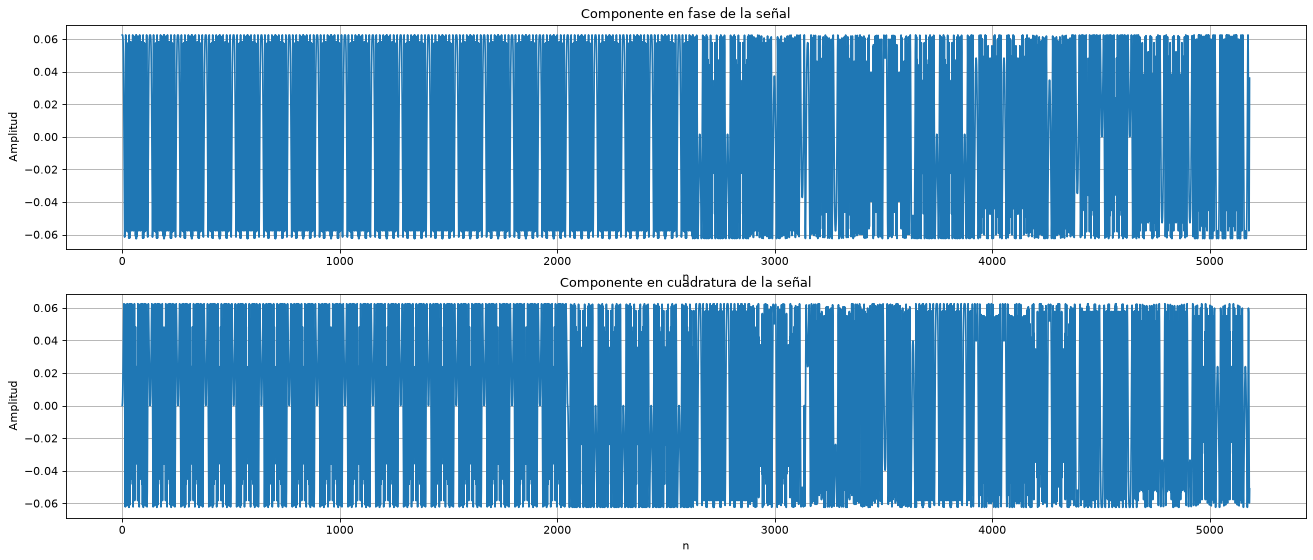

Ahora se grafica la trama completa: el preámbulo seguido por los símbolos del payload. Cada símbolo es un chirp con un desplazamiento cíclico de frecuencia, de acuerdo con la ecuación (1) para el símbolo y las ecuaciones (2)-(3) para la forma de onda. La envolvente sigue siendo aproximadamente constante; los cambios de fase entre símbolos son esperables. Esta es la señal que el transmisor repite de forma cíclica.


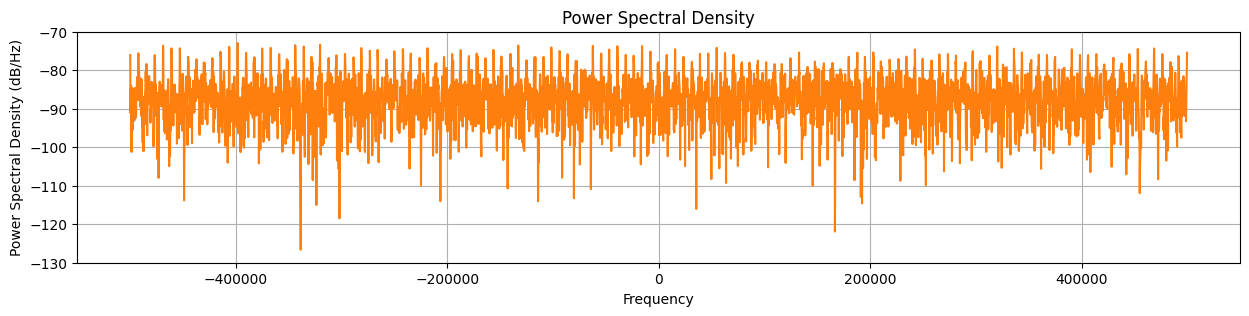

In [8]:
# TRANSMISOR — 7. Densidad espectral de potencia de la trama completa
plotSpect(trama, SamplingRate)

**Densidad espectral de potencia de la trama**

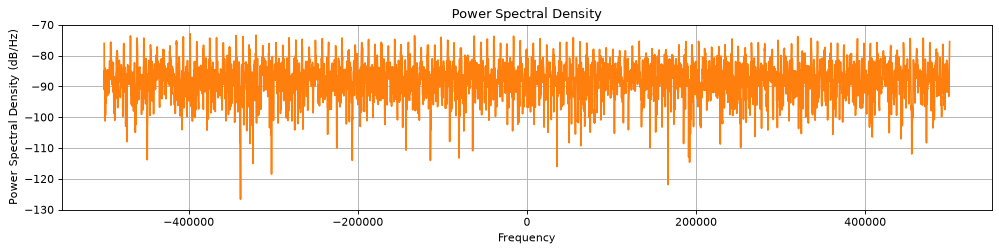

La PSD de la trama completa es prácticamente igual a la del preámbulo: agregar payload no ensancha la banda ni genera componentes fuera de 1 MHz. El payload también está formado por chirps, así que la ocupación espectral queda determinada por las ecuaciones (2)-(3). Sirve para confirmar que la trama completa sigue siendo compatible con el ancho de banda del canal.


In [9]:
# TRANSMISOR — 8. Demodulación (Ecuaciones 15 y 16)
def demodular(recibido, M=M):
    """Demodula uno o varios símbolos por dechirp + FFT."""
    datos = np.asarray(recibido, dtype=np.complex128)
    if datos.ndim == 1:
        if datos.size % M != 0:
            raise ValueError("la señal no es múltiplo de M")
        datos = datos.reshape(-1, M)
    dechirpeado = datos * down_chirp_demod(M)[None, :]
    espectros = np.abs(np.fft.fft(dechirpeado, axis=1))
    return np.argmax(espectros, axis=1)


simbolos_recuperados = demodular(modular(simbolos_payload))
print("Demodulación ida y vuelta:", np.array_equal(simbolos_recuperados, simbolos_payload))

Demodulación ida y vuelta: True


**Demodulación**

Para recuperar un símbolo, el receptor multiplica el chirp recibido por un chirp descendente. Esa operación, llamada *dechirp*, cancela el barrido de frecuencia y deja un tono puro cuya frecuencia coincide con el valor del símbolo. Después se calcula la FFT y se busca el pico más alto: su posición es el símbolo transmitido (ecuaciones (15) y (16)). Como prueba, el payload se modula y se demodula sin ruido; el resultado `True` confirma que se recuperan exactamente los mismos símbolos.

In [10]:
# TRANSMISOR — 9. Armado de la trama: preámbulo + payload
def construir_trama(simbolos, M=M, n_up=n_up, n_down=n_down, cuarto=cuarto_down):
    """Preámbulo seguido del payload modulado."""
    return np.concatenate([preambulo(M, n_up, n_down, cuarto), modular(simbolos, M)])


def longitud_trama(M=M, n_simbolos=n_simbolos, n_up=n_up, n_down=n_down,
                   cuarto=cuarto_down):
    return longitud_preambulo(M, n_up, n_down, cuarto) + n_simbolos * M


trama = construir_trama(simbolos_payload)
print(f"Preámbulo: {preambulo_ref.size} muestras")
print(f"Payload:   {n_simbolos*M} muestras")
print(f"Trama:     {trama.size} muestras ({trama.size/SamplingRate*1e3:.3f} ms)")

Preámbulo: 2624 muestras
Payload:   2560 muestras
Trama:     5184 muestras (5.184 ms)


**Armado de la trama**

La trama es lo que efectivamente se envía: el preámbulo seguido de los 10 símbolos del mensaje. Con los parámetros elegidos, el preámbulo ocupa 2624 muestras y el payload 2560, en total 5184 muestras, unos 5 ms de señal. Esta trama todavía no tiene ruido, portadora ni escalado para el SDR: es la señal ideal que sale del transmisor.

In [11]:
# TRANSMISOR — 10. Detección del preámbulo: correlación en tiempo y en frecuencia
def correlacion_tiempo(recibido, patron=preambulo_ref):
    """Correlación directa en el dominio del tiempo."""
    recibido = np.asarray(recibido, dtype=np.complex128)
    patron = np.asarray(patron, dtype=np.complex128)
    if recibido.size < patron.size:
        raise ValueError("la señal es más corta que el patrón")
    return np.abs(np.correlate(recibido, patron, mode="valid"))


def correlacion_fft(recibido, patron=preambulo_ref, circular=False):
    """|correlación| calculada por FFT. Acepta una captura o un lote 2D."""
    recibido = np.asarray(recibido)
    patron = np.asarray(patron)
    if recibido.shape[-1] < patron.size:
        raise ValueError("la señal es más corta que el patrón")
    if circular:
        # El patrón puede ser más corto que la captura: se rellena con ceros a la
        # longitud de la captura para que la correlación circular tenga el mismo largo.
        producto = np.fft.fft(recibido, axis=-1) * np.conj(
            np.fft.fft(patron, recibido.shape[-1], axis=-1))
        return np.abs(np.fft.ifft(producto, axis=-1))
    n = recibido.shape[-1] + patron.size - 1
    nfft = 1 << (n - 1).bit_length()
    producto = np.fft.fft(recibido, nfft, axis=-1) * np.conj(np.fft.fft(patron, nfft))
    completo = np.fft.ifft(producto, axis=-1)
    return np.abs(completo[..., : recibido.shape[-1] - patron.size + 1])


def detectar_tiempo(recibido, patron=preambulo_ref):
    """Inicio y métrica del preámbulo por correlación temporal."""
    recibido = np.asarray(recibido, dtype=np.complex128)
    correlacion = correlacion_tiempo(recibido, patron)
    inicio = int(np.argmax(correlacion))
    energia = np.sum(np.abs(recibido[inicio: inicio + patron.size]) ** 2)
    metrica = correlacion[inicio] / (np.linalg.norm(patron) * np.sqrt(energia))
    return {"inicio": inicio, "metrica": float(metrica), "correlacion": correlacion}


def detectar_frecuencia(recibido, patron=preambulo_ref, circular=False):
    """Inicio y métrica del preámbulo por correlación en frecuencia (FFT)."""
    recibido = np.asarray(recibido)
    unico = recibido.ndim == 1
    lote = recibido.reshape(1, -1) if unico else recibido
    correlacion = correlacion_fft(lote, patron, circular)
    inicio = np.argmax(correlacion, axis=-1)
    if circular:
        if patron.size == lote.shape[-1]:
            energia = np.sum(np.abs(lote) ** 2, axis=-1)
        else:
            # Energía de la ventana del patrón en cada posición, con vuelta circular.
            potencia = np.abs(lote) ** 2
            doble = np.concatenate([potencia, potencia], axis=-1)
            acumulada = np.cumsum(
                np.concatenate([np.zeros((lote.shape[0], 1), dtype=potencia.dtype), doble],
                               axis=1), axis=1)
            filas = np.arange(lote.shape[0])
            energia = acumulada[filas, inicio + patron.size] - acumulada[filas, inicio]
    else:
        potencia = np.abs(lote) ** 2
        acumulada = np.cumsum(
            np.concatenate([np.zeros((lote.shape[0], 1), dtype=potencia.dtype), potencia], axis=1),
            axis=1)
        filas = np.arange(lote.shape[0])
        energia = acumulada[filas, inicio + patron.size] - acumulada[filas, inicio]
    metrica = correlacion[np.arange(lote.shape[0]), inicio] / (
        np.linalg.norm(patron) * np.sqrt(energia))
    if unico:
        return {"inicio": int(inicio[0]), "metrica": float(metrica[0]),
                "correlacion": correlacion[0]}
    return {"inicio": inicio, "metrica": metrica, "correlacion": correlacion}

**Detección del preámbulo**

El receptor no sabe en qué momento empieza cada trama, así que la busca comparando la señal recibida con una copia del preámbulo en todas las posiciones posibles. Esa comparación es la correlación: donde aparece el preámbulo se forma un pico, y su posición marca el inicio de la trama. Se implementa de dos formas equivalentes, directamente en el tiempo y a través de la FFT, que da el mismo resultado mucho más rápido. Además se calcula una métrica entre 0 y 1 que indica qué tan parecida es la señal al preámbulo.

In [12]:
# CONFIGURACIÓN DEL SDR — se deja el enlace abierto para el receptor
import adi

sdr = adi.Pluto("ip:192.168.1.34")

# Si otra sesión dejó el chip en "alert", el RX no entrega muestras.
if sdr._ctrl.attrs["ensm_mode"].value != "fdd":
    sdr._ctrl.attrs["ensm_mode"].value = "fdd"

sdr.loopback = 0
sdr.sample_rate = int(SamplingRate)
sdr.tx_rf_bandwidth = 2_000_000
sdr.rx_rf_bandwidth = 2_000_000
sdr.tx_hardwaregain_chan0 = -60
sdr.gain_control_mode_chan0 = "slow_attack"
sdr.tx_lo = int(fc)
sdr.rx_lo = int(fc)
sdr.rx_buffer_size = tramas_en_buffer * longitud_trama()
sdr.tx_cyclic_buffer = True

print(f"Enlace configurado: {fc/1e6:.0f} MHz | RX buffer {sdr.rx_buffer_size} muestras")
print("El buffer cíclico se activa antes de transmitir.")

Enlace configurado: 915 MHz | RX buffer 10368 muestras
El buffer cíclico se activa antes de transmitir.


**Configuración del SDR**

Se establece la conexión con el ADALM-PLUTO del grupo y se lo prepara para transmitir y recibir al mismo tiempo. Las dos portadoras se fijan en 915 MHz, la tasa de muestreo en 1 MHz y la potencia de transmisión en un valor bajo. La ganancia de recepción la ajusta automáticamente el control de ganancia del Pluto. Cada captura alcanza para dos tramas, de modo que siempre queda al menos una completa adentro. Por último se activa el modo cíclico, que permite que la trama se repita sola una vez enviada.

In [13]:
# ENVÍO DE LA SEÑAL AL SDR
sdr.tx(trama * (2 ** 15 - 1))
print("Trama transmitida; el buffer cíclico la repite sin pausa.")

Trama transmitida; el buffer cíclico la repite sin pausa.


**Envío de la trama**

La trama se escala al rango de enteros de 16 bits que espera el conversor del Pluto y se envía una sola vez. Gracias al modo cíclico, el SDR la retransmite sin pausa, una tras otra, sin que el programa tenga que volver a mandarla. El enlace queda abierto para que el receptor pueda capturar la señal en cualquier momento.

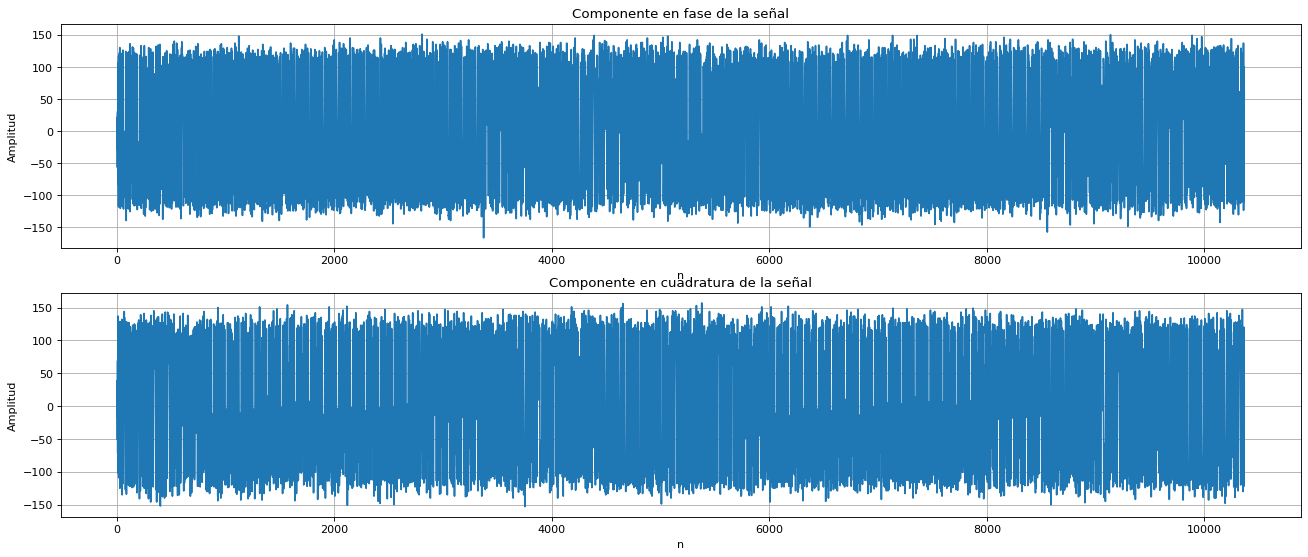

In [14]:
# RECEPTOR — 1. Gráfico de la señal recibida
captura = sdr.rx()
plotSignal(captura)

**Señal recibida en el dominio del tiempo**

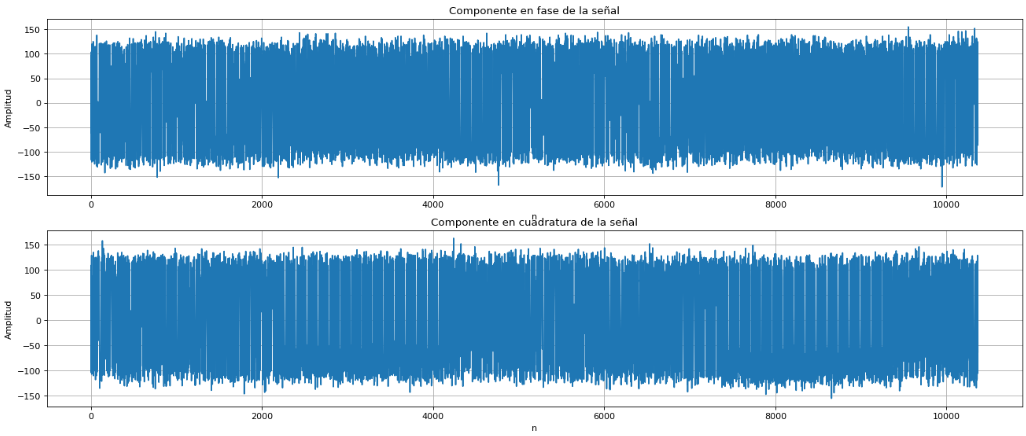

Se grafica la captura real del receptor: dos tramas consecutivas con preámbulo, payload y ruido. La amplitud depende de la ganancia y del AGC del Pluto. La señal recibida responde al modelo de la ecuación (10). Es la entrada que después usa `detectar_frecuencia` para buscar el preámbulo; a simple vista el preámbulo puede quedar tapado por el ruido, y por eso la detección se hace por correlación.


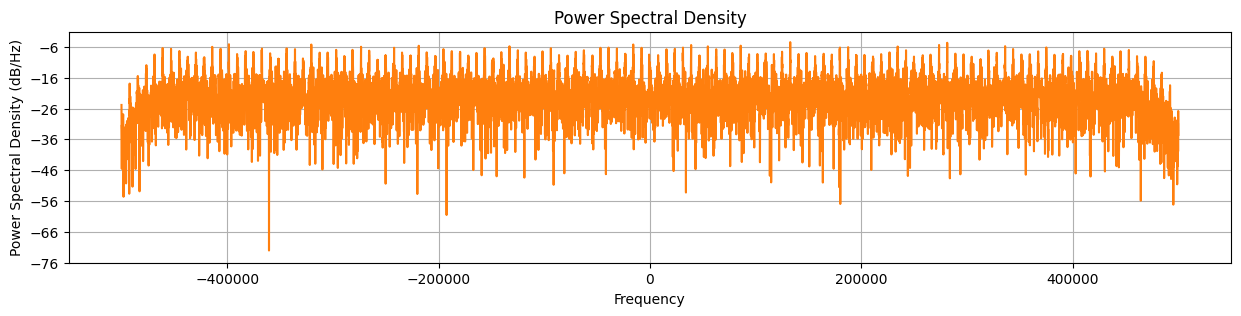

In [15]:
# RECEPTOR — 2. Densidad espectral de potencia de la señal recibida
plotSpect(captura, SamplingRate)

**Densidad espectral de potencia de la señal recibida**

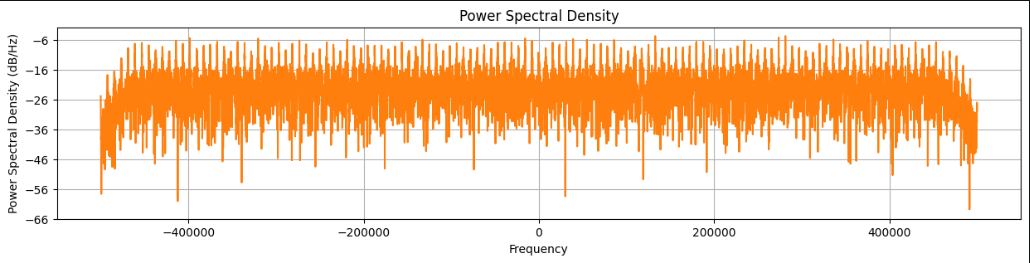

La PSD de la captura muestra la señal ocupando aproximadamente 1 MHz y un piso de ruido repartido en la banda. Es la versión experimental de la ecuación (10): señal más ruido blanco. Comparada con la PSD de la celda 8, permite ver cuánto ruido agregó el enlace y si la señal sigue dentro del ancho de banda esperado.


Inicio de la trama: muestra 748
Símbolos transmitidos: [194, 19, 225, 25, 62, 212, 49, 80, 38, 40]
Símbolos recibidos:    [194, 19, 225, 25, 62, 212, 49, 80, 38, 40]
Símbolos erróneos: 0/10 | bits erróneos: 0/80
Payload recuperado sin errores.


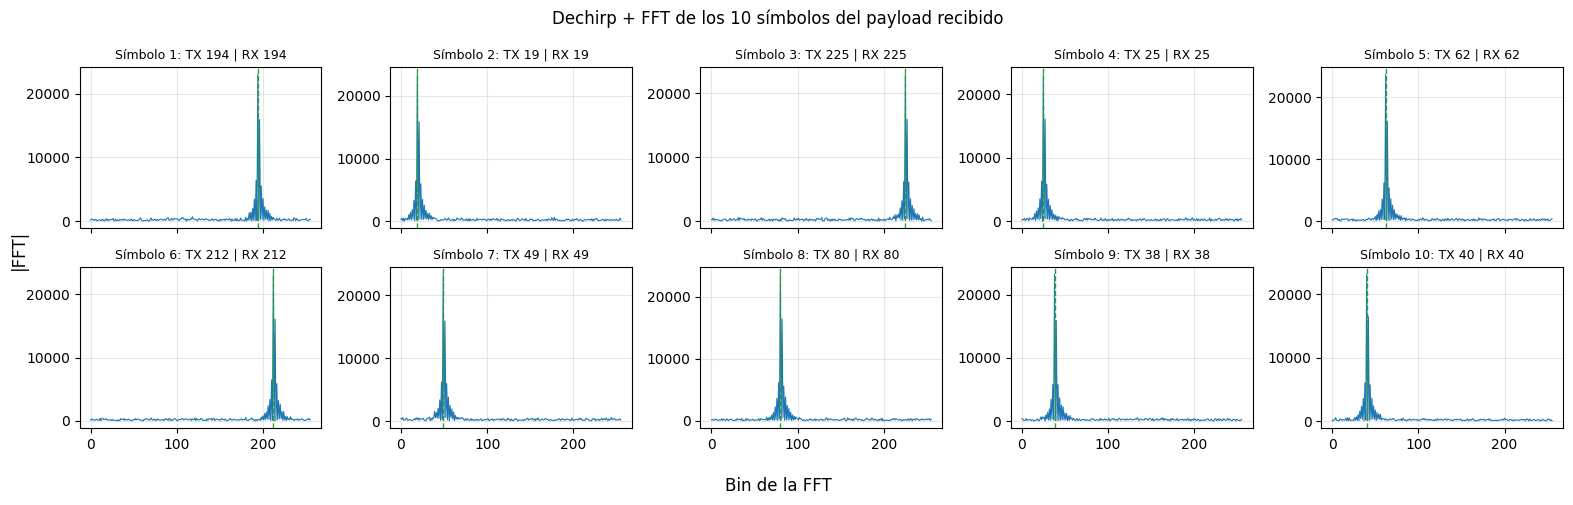

In [16]:
# RECEPTOR — 3. Demodulación del payload de la captura
# Usa la captura del bloque "RECEPTOR — 1" (dos tramas). La trama se repite cada
# largo_trama muestras, así que el inicio se lleva a la primera copia (módulo
# largo_trama): de esa forma el payload siempre entra completo en la captura.
largo_trama = longitud_trama()
largo_preambulo = longitud_preambulo()

correlacion_rx = detectar_frecuencia(captura)["correlacion"]
inicio_rx = int(np.argmax(correlacion_rx)) % largo_trama
comienzo_payload = inicio_rx + largo_preambulo
payload_rx = captura[comienzo_payload: comienzo_payload + n_simbolos * M]

simbolos_rx = demodular(payload_rx)                       # dechirp + FFT + argmax
bits_rx = (simbolos_rx[:, None] >> np.arange(SF)) & 1     # ecuación (1) invertida

errores_simbolo = int(np.count_nonzero(simbolos_rx != simbolos_payload))
errores_bit = int(np.count_nonzero(bits_rx != bits_payload))
print(f"Inicio de la trama: muestra {inicio_rx}")
print(f"Símbolos transmitidos: {simbolos_payload.tolist()}")
print(f"Símbolos recibidos:    {simbolos_rx.tolist()}")
print(f"Símbolos erróneos: {errores_simbolo}/{n_simbolos} | "
      f"bits erróneos: {errores_bit}/{n_simbolos * SF}")
print("Payload recuperado sin errores." if errores_simbolo == 0
      else "El payload llegó con errores.")

# Espectro de cada símbolo después del dechirp: el pico es el símbolo decidido.
espectros_rx = np.abs(np.fft.fft(payload_rx.reshape(n_simbolos, M)
                                 * down_chirp_demod(M), axis=1))
fig, ejes = plt.subplots(2, 5, figsize=(16, 5), sharex=True)
for i, eje in enumerate(ejes.ravel()):
    eje.plot(espectros_rx[i], linewidth=0.8)
    eje.axvline(simbolos_payload[i], color="C2", linestyle="--", linewidth=1)
    eje.set_title(f"Símbolo {i + 1}: TX {simbolos_payload[i]} | RX {simbolos_rx[i]}",
                  fontsize=9)
    eje.grid(alpha=0.3)
fig.supxlabel("Bin de la FFT")
fig.supylabel("|FFT|")
fig.suptitle("Dechirp + FFT de los 10 símbolos del payload recibido")
fig.tight_layout()
plt.show()

**Demodulación del payload recibido**

Con la trama ubicada, el receptor recupera el mensaje. Primero busca el preámbulo en la captura por correlación, igual que en la detección. Como la captura tiene dos tramas y la trama se repite, el inicio se lleva a la primera copia (módulo la longitud de la trama), así el payload entra completo. A partir de ahí se saltean las 2624 muestras del preámbulo y se cortan 10 bloques de 256 muestras. Cada bloque se multiplica por el down-chirp y se le aplica la FFT; la posición del pico es el símbolo (ecuaciones (15) y (16)). Los símbolos se convierten en bits con la ecuación (1) invertida y se comparan con los transmitidos, contando símbolos y bits erróneos. El gráfico muestra el espectro de cada símbolo después del dechirp: la línea punteada marca el símbolo transmitido y, si llegó bien, coincide con el pico.

In [ ]:
# RECEPTOR — 4. FER con 20000 tramas (sin gráfico)
n_tramas_enlace = 20000
umbral_deteccion = 0.5
tramas_ok = 0
tramas_mal = 0

for indice in range(n_tramas_enlace):
    captura = sdr.rx()                 # 2 tramas: preámbulo + payload
    # El patrón es solo el preámbulo; la búsqueda recorre toda la captura.
    info = detectar_frecuencia(captura)
    if info["metrica"] >= umbral_deteccion:
        tramas_ok += 1
    else:
        tramas_mal += 1
    if (indice + 1) % 2000 == 0:
        print(f"{indice + 1}/{n_tramas_enlace} tramas | errores: {tramas_mal}")

fer_enlace = tramas_mal / n_tramas_enlace
print(f"FER con {n_tramas_enlace} tramas: {fer_enlace:.6f}")
print(f"  detectadas: {tramas_ok} | falladas: {tramas_mal}")

FER con 10 tramas: 0.000000
  detectadas: 10 | falladas: 0


**FER en el enlace real**

Se mide qué tan bien funciona la detección sobre la señal real. Como el transmisor repite la misma trama todo el tiempo, cada captura es una nueva observación del mismo paquete. Se toman 20 000 capturas y en cada una se busca el preámbulo con el mismo detector usado en la simulación. Como acá no se conoce la posición verdadera de la trama, se la considera detectada si la métrica de parecido es de al menos 0,5. La FER final es la fracción de capturas falladas. La medición tarda unos 20 minutos.

In [18]:
# CIERRE DEL ENLACE — dejar el Pluto atenuado y fuera de la banda
sdr.tx_destroy_buffer()
sdr.tx_hardwaregain_chan0 = -89
sdr.tx_lo = int(2400e6)
sdr.rx_lo = int(950e6)
sdr.tx(np.zeros(2048, dtype=np.complex128))
print("Enlace cerrado: TX atenuado y portadoras fuera de la banda.")

Enlace cerrado: TX atenuado y portadoras fuera de la banda.


**Cierre del enlace**

Durante toda la práctica el Pluto estuvo transmitiendo la trama sin interrupción: el buffer cíclico la repite por su cuenta, sin que el programa tenga que volver a enviarla. Por eso terminar de ejecutar el notebook no detiene la transmisión, y este bloque se encarga de apagar el transmisor de forma ordenada. Primero se libera el buffer, con lo que la trama deja de repetirse. Como el Pluto no tiene una orden para apagarse, después se baja la potencia de salida al mínimo y se mueven las frecuencias de transmisión y recepción fuera de la banda de 900–920 MHz, que comparten los demás grupos. Por último se envían ceros, así lo único que queda emitiendo es silencio.